<a href="https://colab.research.google.com/github/fidha-rahma/03-02-2026/blob/main/KKA_KELOMPOK.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:

import pandas as pd

df = pd.read_csv('Clothing_Sales_Data.csv')

# Membersihkan spasi pada nama kolom
df.columns = df.columns.str.strip()

# Mengubah kolom tanggal menjadi format datetime
df['saleDate'] = pd.to_datetime(df['saleDate'])

# Statistik penjualan
print("Rata-rata:", df['totalAmount'].mean())
print("Median:", df['totalAmount'].median())
print("Standar deviasi:", df['totalAmount'].std())
print("Kuartil 1 (Q1):", df['totalAmount'].quantile(0.25))
print("Kuartil 3 (Q3):", df['totalAmount'].quantile(0.75))

# Ringkasan statistik
print(df.describe())


Rata-rata: 2716.049851
Median: 2079.135
Standar deviasi: 2087.015522245187
Kuartil 1 (Q1): 1183.03
Kuartil 3 (Q3): 3824.1
                            saleDate      quantity     unitPrice  \
count                          10000  10000.000000  10000.000000   
mean   2023-11-22 01:32:59.868000256      2.004900   1352.842531   
min              2023-01-01 11:50:00      1.000000    200.240000   
25%              2023-06-15 12:45:30      1.000000    783.442500   
50%              2023-11-22 18:48:00      2.000000   1347.545000   
75%              2024-04-28 18:05:00      3.000000   1924.462500   
max              2024-10-11 21:39:00      4.000000   2499.940000   
std                              NaN      1.066016    664.098576   

          costPrice   totalAmount     totalCost  locationLatitude  \
count  10000.000000  10000.000000  10000.000000      10000.000000   
mean    1014.150560   2716.049851   2036.119393         11.179702   
min      121.710000    200.470000    121.710000          8

In [ ]:

# Informasi dataset
print("=== INFORMASI DATASET ===")
df.info()

# Melihat 5 data pertama
print("\n=== 5 DATA PERTAMA ===")
print(df.head())

# Mengecek data kosong
print("\n=== DATA KOSONG ===")
print(df.isnull().sum())

# Mengecek data duplikat
print("\n=== DATA DUPLIKAT ===")
print("Jumlah duplikat:", df.duplicated().sum())

# Jumlah baris dan kolom
print("\n=== UKURAN DATASET ===")
print("Jumlah baris dan kolom:", df.shape)


=== INFORMASI DATASET ===
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 21 columns):
 #   Column             Non-Null Count  Dtype         
---  ------             --------------  -----         
 0   saleID             10000 non-null  object        
 1   saleDate           10000 non-null  datetime64[ns]
 2   productID          10000 non-null  object        
 3   productName        10000 non-null  object        
 4   productCategory    10000 non-null  object        
 5   productColor       10000 non-null  object        
 6   productSize        10000 non-null  object        
 7   quantity           10000 non-null  int64         
 8   unitPrice          10000 non-null  float64       
 9   costPrice          10000 non-null  float64       
 10  totalAmount        10000 non-null  float64       
 11  totalCost          10000 non-null  float64       
 12  customerID         10000 non-null  object        
 13  customerName       10000 non-null  o

In [ ]:
# Mengecek data duplikat
print("Jumlah data duplikat:", df.duplicated().sum())

# Melihat ukuran dataset
print("Jumlah baris dan kolom:", df.shape)

Jumlah data duplikat: 0
Jumlah baris dan kolom: (10000, 21)


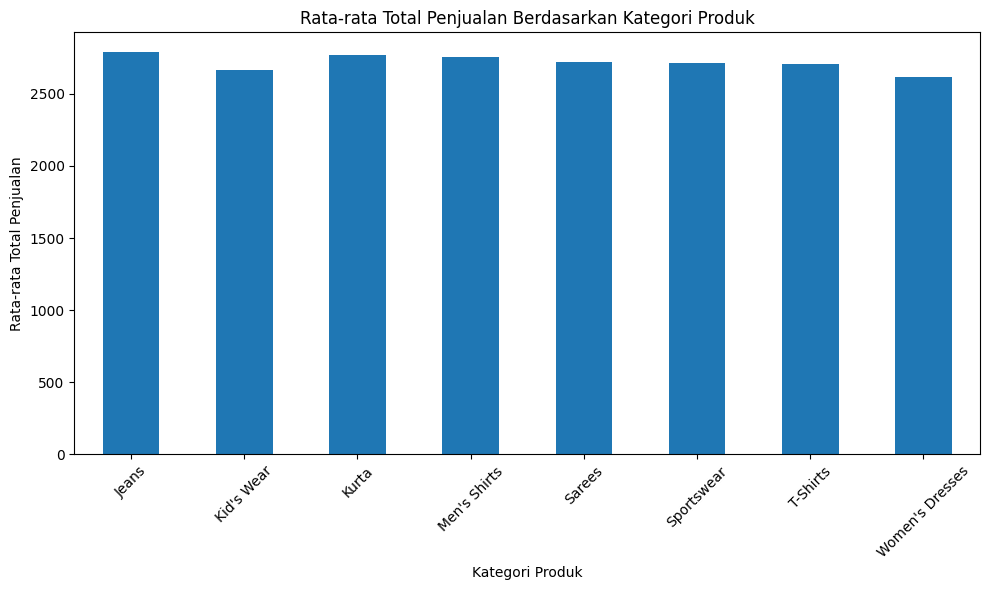

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# Menghitung rata-rata total penjualan berdasarkan kategori
kategori_penjualan = df.groupby('productCategory')['totalAmount'].mean()

# Membuat grafik batang
plt.figure(figsize=(10, 6))
kategori_penjualan.plot(kind='bar')

plt.title('Rata-rata Total Penjualan Berdasarkan Kategori Produk')
plt.xlabel('Kategori Produk')
plt.ylabel('Rata-rata Total Penjualan')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

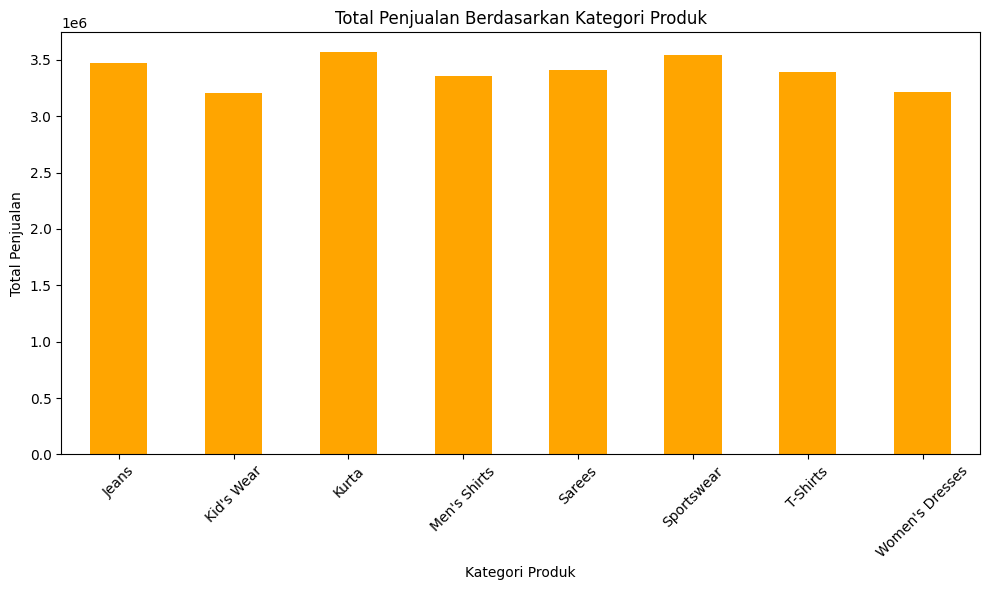

In [ ]:
# Menghitung total penjualan berdasarkan kategori produk
total_penjualan = df.groupby('productCategory')['totalAmount'].sum()

# Membuat grafik batang
plt.figure(figsize=(10, 6))
total_penjualan.plot(kind='bar', color='orange')

plt.title('Total Penjualan Berdasarkan Kategori Produk')
plt.xlabel('Kategori Produk')
plt.ylabel('Total Penjualan')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

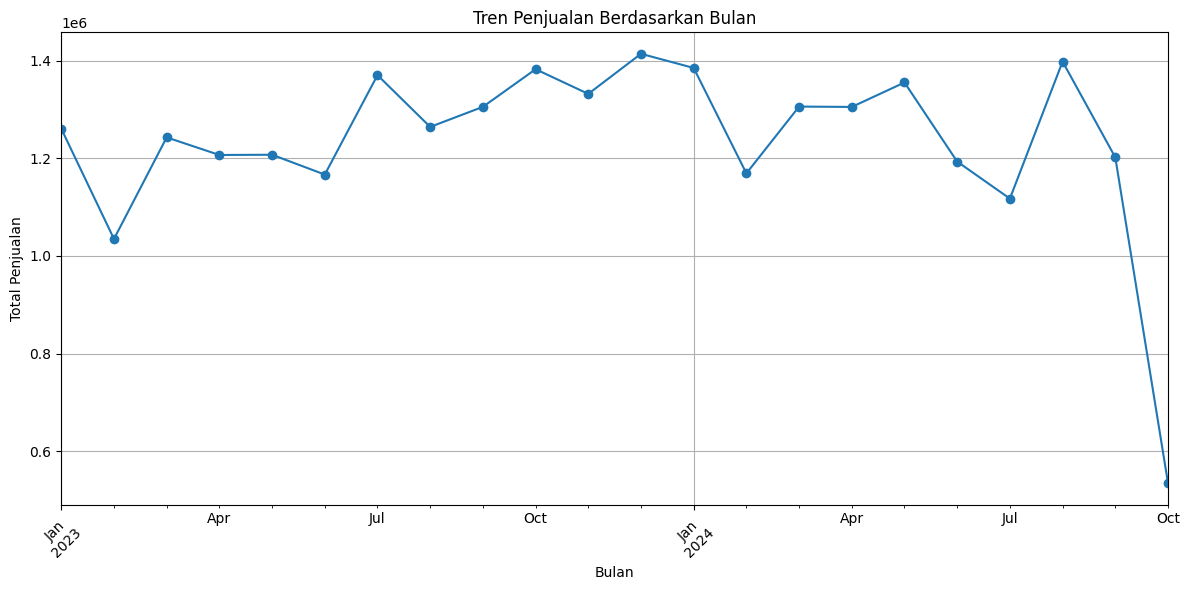

In [ ]:
# Mengambil bulan dan tahun dari tanggal penjualan
df['bulan'] = df['saleDate'].dt.to_period('M')

# Menghitung total penjualan setiap bulan
penjualan_bulanan = df.groupby('bulan')['totalAmount'].sum()

# Membuat grafik garis
plt.figure(figsize=(12, 6))
penjualan_bulanan.plot(kind='line', marker='o')

plt.title('Tren Penjualan Berdasarkan Bulan')
plt.xlabel('Bulan')
plt.ylabel('Total Penjualan')
plt.xticks(rotation=45)
plt.grid(True)
plt.tight_layout()
plt.show()

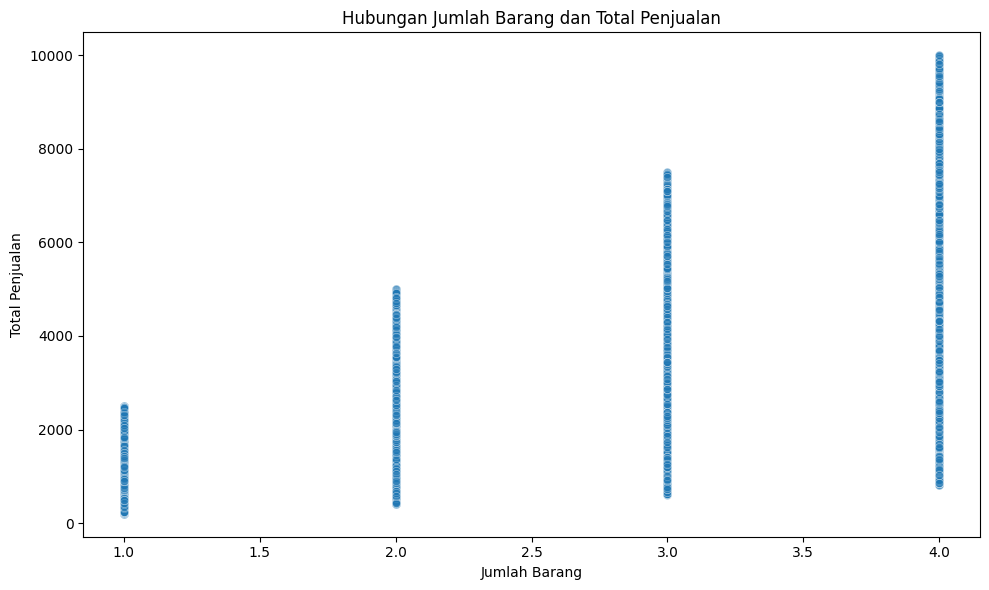

In [ ]:
# Membuat scatter plot
plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=df,
    x='quantity',
    y='totalAmount',
    alpha=0.5
)

plt.title('Hubungan Jumlah Barang dan Total Penjualan')
plt.xlabel('Jumlah Barang')
plt.ylabel('Total Penjualan')
plt.tight_layout()
plt.show()

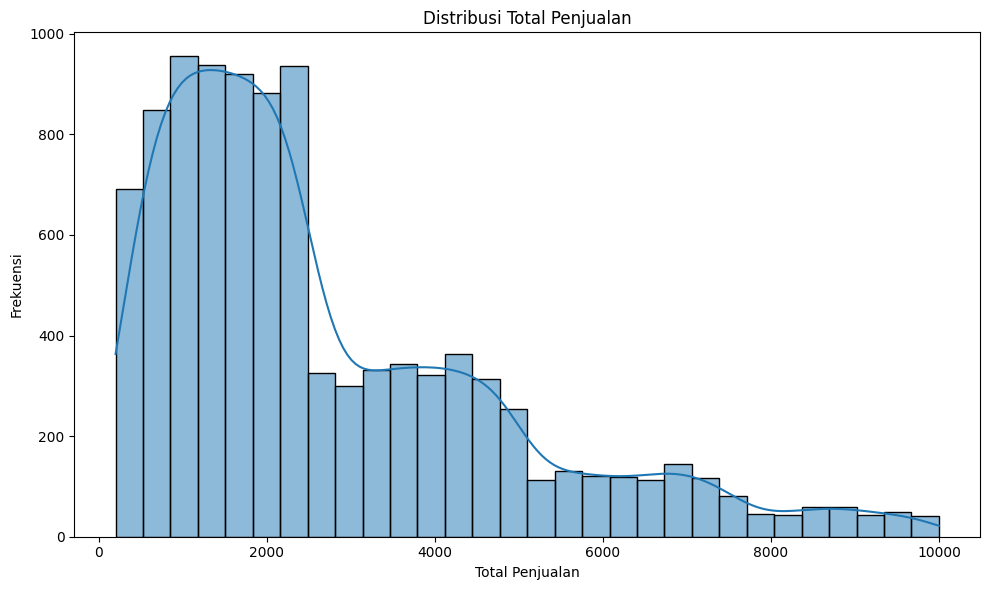

In [ ]:
# Membuat histogram distribusi total penjualan
plt.figure(figsize=(10, 6))

sns.histplot(
    data=df,
    x='totalAmount',
    bins=30,
    kde=True
)

plt.title('Distribusi Total Penjualan')
plt.xlabel('Total Penjualan')
plt.ylabel('Frekuensi')
plt.tight_layout()
plt.show()

In [ ]:
# Menghitung Q1 dan Q3
Q1 = df['totalAmount'].quantile(0.25)
Q3 = df['totalAmount'].quantile(0.75)

# Menghitung IQR
IQR = Q3 - Q1

# Menentukan batas bawah dan batas atas
batas_bawah = Q1 - (1.5 * IQR)
batas_atas = Q3 + (1.5 * IQR)

# Mengidentifikasi outlier
outlier = df[
    (df['totalAmount'] < batas_bawah) |
    (df['totalAmount'] > batas_atas)
]

print("Q1:", Q1)
print("Q3:", Q3)
print("IQR:", IQR)
print("Batas bawah:", batas_bawah)
print("Batas atas:", batas_atas)
print("Jumlah outlier:", len(outlier))

Q1: 1183.03
Q3: 3824.1
IQR: 2641.0699999999997
Batas bawah: -2778.575
Batas atas: 7785.705
Jumlah outlier: 335


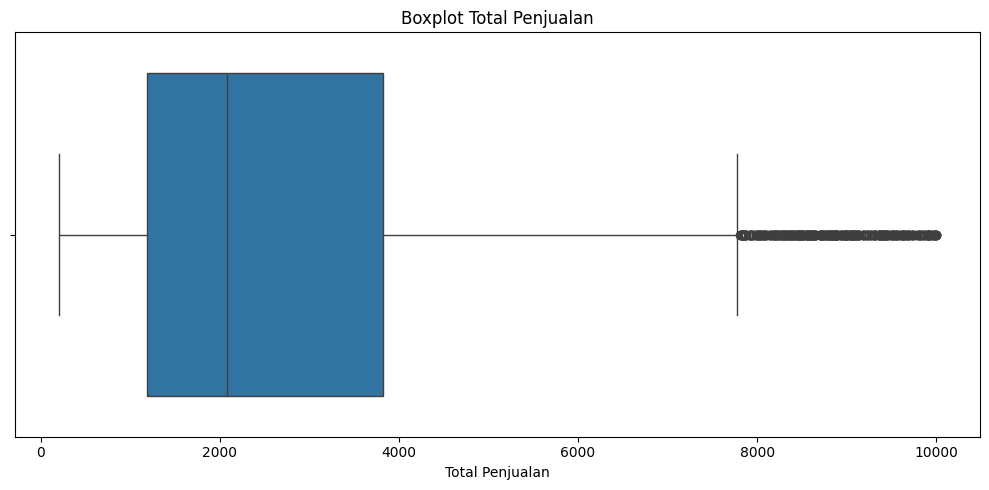

In [ ]:
# Membuat boxplot total penjualan
plt.figure(figsize=(10, 5))

sns.boxplot(
    data=df,
    x='totalAmount'
)

plt.title('Boxplot Total Penjualan')
plt.xlabel('Total Penjualan')
plt.tight_layout()
plt.show()

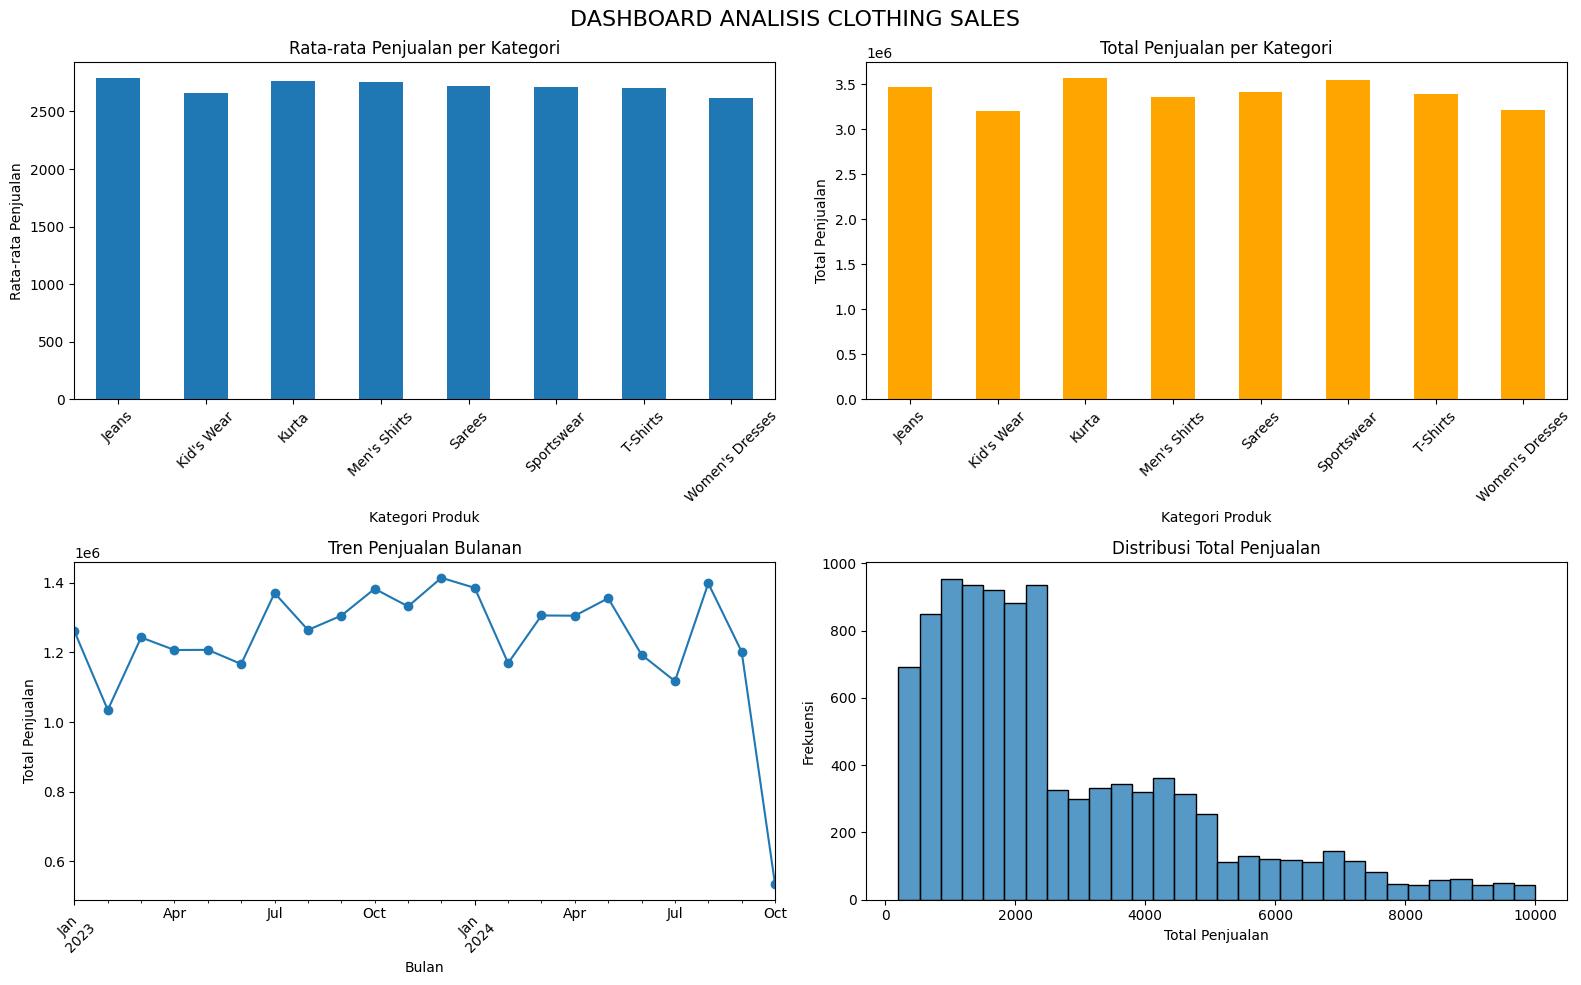

In [ ]:
# Membuat dashboard dengan 4 grafik
fig, axes = plt.subplots(2, 2, figsize=(16, 10))

# Grafik 1: Rata-rata penjualan per kategori
kategori_penjualan.plot(
    kind='bar',
    ax=axes[0, 0],
    title='Rata-rata Penjualan per Kategori'
)
axes[0, 0].set_xlabel('Kategori Produk')
axes[0, 0].set_ylabel('Rata-rata Penjualan')
axes[0, 0].tick_params(axis='x', rotation=45)

# Grafik 2: Total penjualan per kategori
total_penjualan.plot(
    kind='bar',
    ax=axes[0, 1],
    color='orange',
    title='Total Penjualan per Kategori'
)
axes[0, 1].set_xlabel('Kategori Produk')
axes[0, 1].set_ylabel('Total Penjualan')
axes[0, 1].tick_params(axis='x', rotation=45)

# Grafik 3: Tren penjualan bulanan
penjualan_bulanan.plot(
    kind='line',
    marker='o',
    ax=axes[1, 0],
    title='Tren Penjualan Bulanan'
)
axes[1, 0].set_xlabel('Bulan')
axes[1, 0].set_ylabel('Total Penjualan')
axes[1, 0].tick_params(axis='x', rotation=45)

# Grafik 4: Distribusi total penjualan
sns.histplot(
    data=df,
    x='totalAmount',
    bins=30,
    ax=axes[1, 1]
)
axes[1, 1].set_title('Distribusi Total Penjualan')
axes[1, 1].set_xlabel('Total Penjualan')
axes[1, 1].set_ylabel('Frekuensi')

# Mengatur tampilan dashboard
plt.suptitle('DASHBOARD ANALISIS CLOTHING SALES', fontsize=16)
plt.tight_layout()
plt.show()

# Laporan Analisis Data Penjualan Clothing Store

Berdasarkan hasil analisis terhadap 10.000 data transaksi Clothing Store, terdapat 21 kolom yang digunakan untuk melihat kondisi penjualan. Dari pemeriksaan awal, tidak ditemukan data kosong maupun data duplikat. Jadi, dataset tersebut sudah bisa digunakan untuk proses analisis.

Dari grafik rata-rata penjualan berdasarkan kategori produk, Jeans memiliki rata-rata penjualan paling tinggi, sedangkan Women's Dresses memiliki rata-rata paling rendah. Hal ini menunjukkan bahwa nilai transaksi rata-rata setiap kategori produk berbeda-beda.

Grafik total penjualan digunakan untuk mengetahui kategori yang memberikan kontribusi penjualan terbesar. Selain itu, grafik tren bulanan membantu melihat perubahan penjualan dari waktu ke waktu. Grafik hubungan jumlah barang dengan total penjualan juga digunakan untuk mengetahui apakah banyaknya barang yang dibeli berpengaruh terhadap nilai transaksi.

Pada tahap berikutnya, deteksi outlier dilakukan menggunakan metode IQR untuk menemukan transaksi yang nilainya jauh berbeda dari transaksi lainnya. Hasil ini bisa menjadi bahan pemeriksaan lebih lanjut agar data penjualan tetap terpantau.

Berdasarkan hasil analisis, Clothing Store sebaiknya menjaga ketersediaan produk yang memiliki rata-rata penjualan tinggi. Kategori dengan penjualan lebih rendah juga perlu dievaluasi, misalnya melalui promosi atau strategi pemasaran yang lebih menarik. Selain itu, perubahan penjualan setiap bulan perlu diperhatikan agar toko dapat menentukan strategi yang tepat. Dengan memanfaatkan data transaksi, keputusan bisnis bisa dibuat dengan lebih terarah.